# 계절성 검사 및 알고리즘 자동 매칭 데모

## 구현 흐름

1. 예제 시계열 데이터를 생성하거나 실제 CSV 파일을 지정한다.
2. 시간 정보를 날짜 자료형으로 변환하고 시간순으로 정렬한다.
3. 시간 간격을 추정하여 시계열 데이터인지 판단한다.
4. 시간 간격에 따라 계절 주기를 룰베이스로 자동 결정한다.
5. 계절성 검사 결과에 따라 데이터셋 태그를 생성한다.
6. 데이터셋과 알고리즘 정보를 하나의 통합 JSON으로 저장한다.
7. 통합 JSON을 다시 읽어 데이터셋 태그와 알고리즘 필수 태그를 비교한다.
8. 적용 가능한 알고리즘을 목록에 추가한다.
9. 적용 가능한 알고리즘을 각각 실행한다.
10. 시간, 원본값, 분해값, 이상치 여부를 CSV로 저장한다.

> 시계열 여부를 판단할 때 데이터 길이는 사용하지 않는다. 데이터 길이는 알고리즘 실행 직전의 오류 방지 조건으로만 확인한다.

In [1]:
# 필요한 라이브러리 설치
%pip install pandas numpy statsmodels matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. 라이브러리 및 경로 설정

데이터 처리에는 pandas와 NumPy를 사용하고, 시계열 분해에는 statsmodels의 STL을 사용한다.

이번 수정본에서는 메타데이터를 여러 JSON으로 나누지 않고 `integrated_metadata.json` 하나에 저장한다. 알고리즘 실행 결과는 JSON이 아닌 CSV로 저장한다.

In [2]:
# 라이브러리 불러오기
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL


# 현재 주피터 노트북이 실행되는 위치
BASE_DIR = Path.cwd()

# 파일 종류별 저장 폴더
DATA_DIR = BASE_DIR / "data"
METADATA_DIR = BASE_DIR / "metadata"
RESULT_DIR = BASE_DIR / "results"

# 폴더가 없으면 생성
DATA_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("기준 경로:", BASE_DIR)
print("데이터 폴더:", DATA_DIR)
print("메타데이터 폴더:", METADATA_DIR)
print("결과 폴더:", RESULT_DIR)

기준 경로: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)
데이터 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\data
메타데이터 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata
결과 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results


## 2. 계절성이 있는 월별 예제 데이터 생성

코드의 자동화 흐름을 확인하기 위해 5년 동안의 월별 예제 데이터를 생성한다.

- 장기적으로 증가하는 추세
- 12개월마다 반복되는 계절성
- 실제 데이터와 비슷하게 만들기 위한 무작위 잡음

실제 데이터를 사용할 때는 아래 예제 생성 셀 대신 `data_path`, `time_column`, `value_column`만 실제 파일에 맞게 지정하면 된다.

In [3]:
# 실행할 때마다 동일한 난수가 나오도록 고정
np.random.seed(42)

# 2020년 1월부터 60개월의 월별 날짜 생성
dates = pd.date_range(
    start="2020-01-01",
    periods=60,
    freq="MS",  # 매월 시작일 간격
)

# 0부터 59까지의 시간 순서
time_index = np.arange(60)

# 시간이 흐를수록 증가하는 추세
trend = 100 + time_index * 0.5

# 12개월마다 반복되는 계절성 패턴
seasonal_pattern = (
    20
    * np.sin(
        2 * np.pi
        * time_index / 12
    )
)

# 실제 데이터와 비슷하게 만들기 위한 무작위 잡음
noise = np.random.normal(
    loc=0,
    scale=3,
    size=60,
)

# 원래 코드에서 새롭게 추가
# 이상치 검출 결과를 확인하기 위해 일부 값에 큰 변화 추가
anomaly_noise = np.zeros(60)
anomaly_noise[[18, 43]] = [45, -50] # 18번 월과 43번 월에 큰 이상치 추가
# 18번에는 45를 더하고, 43번에는 -50을 더하여 이상치를 생성

# 최종 관측값
values = (
    trend
    + seasonal_pattern
    + noise
    + anomaly_noise # 이상치 추가
)

# 날짜별 관측값을 가진 예제 데이터 생성
demo_df = pd.DataFrame({
    "date": dates,
    "value": values,
})

# 예제 데이터 저장 경로
data_path = DATA_DIR / "seasonal_demo.csv"

# CSV 파일로 저장
demo_df.to_csv(
    data_path,
    index=False,
    encoding="utf-8-sig",
)

# 분석에 사용할 컬럼 지정
# 실제 CSV를 사용할 때에는 아래 세 값만 수정
time_column = "date"
value_column = "value"
dataset_id = "SEASONAL_DEMO_01"

print("예제 데이터 저장 완료:", data_path)
display(demo_df.head())

예제 데이터 저장 완료: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\data\seasonal_demo.csv


,date,value
0,2020-01-01,101.490142
1,2020-02-01,110.085207
2,2020-03-01,120.263574
3,2020-04-01,126.069090
4,2020-05-01,118.618048


## 3. 데이터 읽기 및 시간 정보 정렬

CSV 파일을 읽은 뒤 시간 컬럼을 `datetime`, 분석 대상 컬럼을 숫자 자료형으로 변환한다.

시간 컬럼을 오름차순으로 정렬하고 `is_monotonic_increasing`을 사용해 실제로 시간순 정렬이 되었는지 확인한다.

In [4]:
# CSV 데이터 읽기
dataset_df = pd.read_csv(
    data_path,
    encoding="utf-8-sig",
)

# 시간 정보를 날짜 자료형으로 변환
dataset_df[time_column] = pd.to_datetime(
    dataset_df[time_column],
    errors="coerce",  # 날짜로 바꿀 수 없는 값은 NaT 처리
)

# 분석값을 숫자 자료형으로 변환
dataset_df[value_column] = pd.to_numeric(
    dataset_df[value_column],
    errors="coerce",  # 숫자로 바꿀 수 없는 값은 NaN 처리
)

# 시간순으로 정렬
dataset_df = (
    dataset_df
    .sort_values(time_column)
    .reset_index(drop=True)
)

# 시간 정보가 과거에서 최근 순서로 정렬되었는지 확인
is_time_sorted = (
    dataset_df[time_column]
    .is_monotonic_increasing
)

print("데이터 크기:", dataset_df.shape)
print("시간순 정렬 여부:", is_time_sorted)
print("\n자료형:")
print(dataset_df.dtypes)

display(dataset_df.head())

데이터 크기: (60, 2)
시간순 정렬 여부: True

자료형:
date     datetime64[ns]
value           float64
dtype: object


,date,value
0,2020-01-01,101.490142
1,2020-02-01,110.085207
2,2020-03-01,120.263574
3,2020-04-01,126.069090
4,2020-05-01,118.618048


## 4. 시계열 구조 검사 및 계절 주기 자동 결정

시계열 여부는 다음 조건으로 판단한다.

1. 시간 컬럼이 날짜 자료형이다.
2. 분석 대상 컬럼이 숫자형이다.
3. 시간 정보가 오름차순으로 정렬되어 있다.
4. 관측 간격이 일정하다.

데이터 길이는 시계열 여부를 판단하는 조건에서 제외한다.

계절 주기는 시간 간격에 따라 룰베이스로 자동 결정한다.

| 시간 간격 | 의미 | 계절 주기 |
|---|---|---:|
| `MS` | 월초 기준 월별 데이터 | 12 |
| `ME`, `M` | 월말 기준 월별 데이터 | 12 |
| `D` | 일별 데이터 | 365 |

In [5]:
# 날짜 컬럼을 인덱스로 사용하는 시계열 생성
series = (
    dataset_df
    .set_index(time_column)[value_column]
    .sort_index()
)

# 날짜 간격 추정 
inferred_frequency = pd.infer_freq( # pd.infer_freq() 함수는 날짜들을 보고 관측 간격을 자동으로 추정함
    series.index
)


# 피드백 반영 (계절 주기 직접 설정 > 날짜 간격을 추정한 뒤 자동으로 주기 결정)
def get_seasonal_period(frequency):
    '''
    추정된 시간 간격에 따라
    계절 주기를 룰베이스로 자동 결정한다.
    '''

    # 시간 간격이 없는 경우 > None 반환
    if frequency is None:
        return None


    # 시간 간격 존재
    # 시간 간격을 대문자 문자열로 통일
    normalized_frequency = str(
        frequency
    ).upper()

    # 월초, 월말 기준 월별 데이터는 1년인 12개월을 주기로 사용
    if normalized_frequency in [
        "MS",
        "ME",
        "M",
    ]:
        return 12

    # 일별 데이터는 1년인 365일을 주기로 사용
    if normalized_frequency == "D":
        return 365

    # 정의하지 않은 시간 간격은 주기를 결정하지 않음
    return None


# 시간 간격에 따라 계절 주기 자동 결정
seasonal_period = get_seasonal_period(
    inferred_frequency
)

# 자료형 확인
is_datetime = pd.api.types.is_datetime64_any_dtype(
    dataset_df[time_column]
)

is_numeric = pd.api.types.is_numeric_dtype(
    dataset_df[value_column]
)

# 피드백 반영 (시간 간격이 추정되면 규칙적인 간격으로 판단)
is_regular_interval = (
    inferred_frequency is not None
)

# 결측값 확인
has_no_missing_values = (
    dataset_df[
        [time_column, value_column]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

# 시계열 여부 판단
# 데이터 길이는 이 조건에 포함하지 않음 (피드백 반영)
is_time_series = all([
    is_datetime,
    is_numeric,
    is_time_sorted,
    is_regular_interval,
])

print("추정 시간 간격:", inferred_frequency)
print("자동 결정 계절 주기:", seasonal_period)
print("시간순 정렬 여부:", is_time_sorted)
print("일정한 시간 간격:", is_regular_interval)
print("결측값 없음:", has_no_missing_values)
print("시계열 여부:", is_time_series)

추정 시간 간격: MS
자동 결정 계절 주기: 12
시간순 정렬 여부: True
일정한 시간 간격: True
결측값 없음: True
시계열 여부: True


## 5. 계절성 검사

먼저 선형 추세를 제거한 뒤, 자동으로 결정된 계절 주기만큼 떨어진 값들의 상관성을 계산한다.

계절성 점수가 0.5 이상이면 계절성이 있다고 판단한다. 데이터 길이는 시계열 여부에는 사용하지 않지만, 실제 계절성 계산이 불가능할 정도로 짧은 경우에는 검사 결과를 `False`로 반환한다.

In [6]:
def check_seasonality(
    series, # 계절성을 검사할 시계열
    period, # 반복 주기
    threshold=0.5, # 계절성 판정 기준값
):
    '''
    선형 추세를 제거한 뒤,
    지정한 주기만큼 떨어진 값들의 상관성을 계산한다.
    '''

    # 룰베이스에서 계절 주기를 결정하지 못한 경우 
    # - > 지원하지 않는 시간 간격이면 계절성 검사를 억지로 수행하지 않음
    if period is None:
        return {
            "method": "detrended_lag_correlation",
            "period": None,
            "score": None, # 계절성 점수가 None이면 계절성 판정 불가
            "threshold": float(threshold),
            "detected": False,
            "reason": "시간 간격에 맞는 계절 주기 규칙이 없습니다.",
        }

    # 시계열 값 정리 _ 결측값 제거 후 숫자형으로 변환
    clean_series = (
        pd.Series(series)
        .dropna()
        .astype(float)
        .reset_index(drop=True)
    )

    # 상관성 계산에는 최소 두 주기 분량이 필요
    minimum_length = period * 2

    if len(clean_series) < minimum_length:
        return {
            "method": "detrended_lag_correlation",
            "period": int(period),
            "score": None,
            "threshold": float(threshold),
            "detected": False,
            "reason": "계절성 검사에 필요한 데이터가 부족합니다.",
        }

    # 시간 순서를 0, 1, 2, ... 형태로 생성
    x = np.arange(
        len(clean_series)
    )

    # 데이터에 가장 잘 맞는 1차 직선의 계수 계산
    trend_coefficients = np.polyfit(
        x,
        clean_series,
        deg=1,
    )

    # 각 시점의 선형 추세값 계산
    estimated_trend = np.polyval(
        trend_coefficients,
        x,
    )

    # 원래 값에서 추세를 제거 ( 추세 제거 이유 : 계절성만을 확인하기 위해 )
    detrended_values = (
        clean_series.to_numpy()
        - estimated_trend
    )

    # period(주기)만큼 떨어진 두 값 집합 생성
    previous_values = (
        detrended_values[:-period]
    )

    current_values = (
        detrended_values[period:]
    )

    # 변화가 없는 데이터는 상관계수를 0으로 처리
    if (
        np.std(previous_values) == 0
        or np.std(current_values) == 0
    ):
        score = 0.0

    else:
        score = float(
            np.corrcoef(
                previous_values,
                current_values,
            )[0, 1]
        )

    # 기준값 이상이면 계절성 존재
    detected = bool(
        score >= threshold
    )

    return {
        "method": "detrended_lag_correlation",
        "period": int(period),
        "score": score,
        "threshold": float(threshold),
        "detected": detected,
        "reason": (
            "반복 상관성이 기준 이상입니다."
            if detected
            else "반복 상관성이 기준보다 낮습니다."
        ),
    }


# 계절성 판정 기준
seasonality_threshold = 0.5

# 계절성 검사 실행
seasonality_result = check_seasonality(
    series=series,
    period=seasonal_period,
    threshold=seasonality_threshold,
)

print(json.dumps(
    seasonality_result,
    ensure_ascii=False,
    indent=2,
))

{
  "method": "detrended_lag_correlation",
  "period": 12,
  "score": 0.644166950196447,
  "threshold": 0.5,
  "detected": true,
  "reason": "반복 상관성이 기준 이상입니다."
}


## 6. 데이터셋 태그 생성

시계열 구조와 계절성 검사 결과에 따라 데이터셋 태그를 자동으로 생성한다.

- `time-series`: 시계열 데이터
- `monthly`: 월별 데이터
- `daily`: 일별 데이터
- `numeric-target`: 숫자형 분석값
- `regular-interval`: 일정한 시간 간격
- `seasonal`: 계절성 존재

데이터 길이에 관한 태그는 생성하지 않는다.

In [7]:
# 데이터셋 태그를 저장할 빈 리스트
dataset_tags = []

# 시계열 태그 추가
if is_time_series:
    dataset_tags.append(
        "time-series"
    )

# 주기 데이터 태그
if inferred_frequency in [
    "MS",
    "ME",
    "M",
]:
    dataset_tags.append(
        "monthly" #월별
    )

if inferred_frequency == "D":
    dataset_tags.append(
        "daily" # 일별
    )

# 숫자형 데이터 태그
if is_numeric:
    dataset_tags.append(
        "numeric-target" 
    )

# 규칙적인 간격 여부 태그
if is_regular_interval:
    dataset_tags.append(
        "regular-interval" # 규칙
    )
else:
    dataset_tags.append( 
        "irregular-interval" # 불규칙
    )

# 계절성 태그 추가
if seasonality_result["detected"]:
    dataset_tags.append(
        "seasonal" # 계절성
    )
else:
    dataset_tags.append(
        "non-seasonal" # 비계절성
    )

# 중복 제거 후 정렬
dataset_tags = sorted(
    set(dataset_tags)
)

print("생성 태그:", dataset_tags)

생성 태그: ['monthly', 'numeric-target', 'regular-interval', 'seasonal', 'time-series']


## 7. 통합 메타데이터 JSON 생성

데이터셋 메타데이터와 알고리즘 메타데이터를 별도 JSON으로 저장하지 않는다.

`integrated_metadata.json`에는 다음 두 목록만 저장한다.

- `datasets`: 데이터셋 정보와 태그
- `algorithms`: 알고리즘 정보와 필수 태그

현재는 STL과 IQR 두 알고리즘을 등록한다. 이후 다른 알고리즘을 추가해도 같은 구조로 자동 매칭할 수 있다.

In [8]:
# 데이터셋 메타데이터
dataset_metadata = {
    "dataset_id": dataset_id,
    "dataset_name": "월별 계절성 예제 데이터",
    "source_file": data_path.name,
    "schema": {
        "row_count": int(
            len(dataset_df)
        ),
        "time_column": time_column,
        "value_column": value_column,
    },
    "time_series": {
        "is_time_series": bool(
            is_time_series
        ),
        "is_time_sorted": bool(
            is_time_sorted
        ),
        "frequency": inferred_frequency,
        "is_regular_interval": bool(
            is_regular_interval
        ),
        "seasonal_period": seasonal_period,
        "start_date": (
            series.index.min()
            .strftime("%Y-%m-%d")
        ),
        "end_date": (
            series.index.max()
            .strftime("%Y-%m-%d")
        ),
    },
    "seasonality": seasonality_result,
    "tags": dataset_tags,
}

# STL 알고리즘 메타데이터
stl_metadata = {
    "algorithm_id": "STL_01",
    "algorithm_name": "STL",
    "category": "time-series-anomaly-detection",
    "required_tags": [
        "time-series",
        "numeric-target",
        "regular-interval",
        "seasonal",
    ],
    "parameters": {
        # period는 데이터 시간 간격에 따라 실행할 때 자동 입력
        "period_source": "dataset.time_series.seasonal_period",
        "robust": True,
        "anomaly_method": "residual_z_score",
        "residual_z_threshold": 3.0,
    },
    "outputs": [
        "time",
        "value",
        "trend",
        "seasonal",
        "residual",
        "anomaly_score",
        "is_anomaly",
    ],
    "output_file": "stl_anomaly_result.csv",
}

# IQR 알고리즘 메타데이터
iqr_metadata = {
    "algorithm_id": "IQR_01",
    "algorithm_name": "IQR",
    "category": "numeric-anomaly-detection",
    "required_tags": [
        "numeric-target",
    ],
    "parameters": {
        "iqr_multiplier": 1.5,
    },
    "outputs": [
        "time",
        "value",
        "lower_bound",
        "upper_bound",
        "anomaly_score",
        "is_anomaly",
    ],
    "output_file": "iqr_anomaly_result.csv",
}

# 통합 JSON에는 데이터셋과 알고리즘 목록만 저장
integrated_metadata = {
    "datasets": [
        dataset_metadata
    ],
    "algorithms": [
        stl_metadata,
        iqr_metadata,
    ],
}

# 통합 메타데이터 저장 경로
integrated_metadata_path = (
    METADATA_DIR
    / "integrated_metadata.json"
)

# 통합 JSON 저장
with open(
    integrated_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        integrated_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "통합 메타데이터 저장:",
    integrated_metadata_path,
)

print(json.dumps(
    integrated_metadata,
    ensure_ascii=False,
    indent=2,
))

통합 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\integrated_metadata.json
{
  "datasets": [
    {
      "dataset_id": "SEASONAL_DEMO_01",
      "dataset_name": "월별 계절성 예제 데이터",
      "source_file": "seasonal_demo.csv",
      "schema": {
        "row_count": 60,
        "time_column": "date",
        "value_column": "value"
      },
      "time_series": {
        "is_time_series": true,
        "is_time_sorted": true,
        "frequency": "MS",
        "is_regular_interval": true,
        "seasonal_period": 12,
        "start_date": "2020-01-01",
        "end_date": "2024-12-01"
      },
      "seasonality": {
        "method": "detrended_lag_correlation",
        "period": 12,
        "score": 0.644166950196447,
        "threshold": 0.5,
        "detected": true,
        "reason": "반복 상관성이 기준 이상입니다."
      },
      "tags": [
        "monthly",
        "numeric-target",
        "regular-interval",
        "sea

## 8. 통합 JSON에서 태그를 읽어 알고리즘 매칭

앞에서 사용한 파이썬 변수를 직접 비교하지 않고, 저장된 `integrated_metadata.json`을 다시 읽는다.

데이터셋 태그에 알고리즘의 모든 필수 태그가 포함되어 있으면 `applicable_algorithms` 목록에 해당 알고리즘을 추가한다.

In [9]:
# 저장된 통합 JSON을 다시 읽기
with open(
    integrated_metadata_path,
    "r",
    encoding="utf-8",
) as file:
    loaded_metadata = json.load(
        file
    )

# 첫 번째 데이터셋 정보 가져오기
loaded_dataset = (
    loaded_metadata["datasets"][0]
)

# 통합 JSON에 등록된 전체 알고리즘 목록
loaded_algorithms = (
    loaded_metadata["algorithms"]
)

# 데이터셋이 가진 태그를 집합으로 변환
dataset_tag_set = set(
    loaded_dataset["tags"]
)

# 적용 가능한 알고리즘을 저장할 빈 목록
applicable_algorithms = []

# 등록된 알고리즘을 하나씩 확인
for algorithm in loaded_algorithms:
    # 현재 알고리즘이 요구하는 필수 태그
    required_tag_set = set(
        algorithm["required_tags"]
    )

    # 데이터셋에 없는 필수 태그 계산
    missing_tags = sorted(
        required_tag_set
        - dataset_tag_set
    )

    # 누락된 필수 태그가 없으면 적용 가능한 목록에 추가
    if len(missing_tags) == 0:
        applicable_algorithms.append(
            algorithm
        )

    print(
        algorithm["algorithm_name"],
        "매칭 결과:",
        len(missing_tags) == 0,
    )
    print("누락 태그:", missing_tags)

# 적용 가능한 알고리즘 이름 출력
applicable_algorithm_names = [
    algorithm["algorithm_name"]
    for algorithm in applicable_algorithms
]

print(
    "적용 가능한 알고리즘:",
    applicable_algorithm_names,
)

STL 매칭 결과: True
누락 태그: []
IQR 매칭 결과: True
누락 태그: []
적용 가능한 알고리즘: ['STL', 'IQR']


## 9. 적용 가능한 알고리즘 실행 및 이상치 검출

`applicable_algorithms`에 들어 있는 알고리즘을 하나씩 실행한다.

- STL: 시계열을 추세, 계절성, 잔차로 분해하고 잔차의 Z-score가 3보다 크면 이상치로 판정한다.
- IQR: 원본 관측값이 `Q1 - 1.5 × IQR`보다 작거나 `Q3 + 1.5 × IQR`보다 크면 이상치로 판정한다.

각 알고리즘의 전체 결과와 이상치 여부를 별도의 CSV 파일로 저장한다.

In [10]:
# 알고리즘별 결과 파일 경로를 저장할 목록
result_files = []

# 알고리즘별 이상치 결과를 저장할 딕셔너리
anomaly_results = {}

# 적용 가능한 알고리즘을 하나씩 실행
for algorithm in applicable_algorithms:

    # 현재 실행할 알고리즘 이름
    algorithm_name = (
        algorithm["algorithm_name"]
    )

    print("실행 알고리즘:", algorithm_name)

    # STL 기반 이상 탐지
    if algorithm_name == "STL":

        # 통합 JSON의 데이터셋 정보에서 계절 주기 가져오기
        period = loaded_dataset[
            "time_series"
        ]["seasonal_period"]

        # 알고리즘 메타데이터에서 잔차 Z-score 기준값 가져오기
        residual_z_threshold = (
            algorithm["parameters"]
            ["residual_z_threshold"]
        )

        # 데이터 길이는 시계열 판정에 사용하지 않고
        # STL 실행 오류를 막기 위한 조건으로만 확인
        if (
            period is None
            or len(series) < period * 2
        ):
            print(
                "STL 실행에 필요한 데이터 길이가 부족합니다."
            )
            continue

        # STL 모델 생성 및 실행
        stl_result = STL(
            series,
            period=period,
            robust=True,
        ).fit()

        # 시간별 STL 분해 결과를 표 형태로 구성
        stl_result_df = pd.DataFrame({
            "time": (
                series.index
                .strftime("%Y-%m-%d")
            ),
            "value": (
                stl_result.observed
                .astype(float)
                .to_numpy()
            ),
            "trend": (
                stl_result.trend
                .astype(float)
                .to_numpy()
            ),
            "seasonal": (
                stl_result.seasonal
                .astype(float)
                .to_numpy()
            ),
            "residual": (
                stl_result.resid
                .astype(float)
                .to_numpy()
            ),
        })

        # STL 잔차의 평균과 표준편차 계산
        residual_mean = (
            stl_result_df["residual"]
            .mean()
        )

        residual_std = (
            stl_result_df["residual"]
            .std(ddof=0)
        )

        # 잔차가 평균에서 표준편차 몇 배만큼 떨어졌는지 계산
        if residual_std == 0:
            stl_result_df["anomaly_score"] = 0.0
        else:
            stl_result_df["anomaly_score"] = (
                (
                    stl_result_df["residual"]
                    - residual_mean
                )
                / residual_std
            ).abs()

        # 잔차 Z-score가 기준값보다 크면 이상치
        stl_result_df["is_anomaly"] = (
            stl_result_df["anomaly_score"]
            > residual_z_threshold
        )

        # 실행한 알고리즘 이름 추가
        stl_result_df["algorithm"] = algorithm_name

        # STL 결과 CSV 저장
        stl_result_path = (
            RESULT_DIR
            / algorithm["output_file"]
        )

        stl_result_df.to_csv(
            stl_result_path,
            index=False,
            encoding="utf-8-sig",
        )

        result_files.append(stl_result_path)

        # 이상치 행만 추출
        stl_anomaly_df = (
            stl_result_df[
                stl_result_df["is_anomaly"]
            ]
            .copy()
        )

        anomaly_results["STL"] = stl_anomaly_df

        print("STL 실행 완료")
        print("전체 결과 수:", len(stl_result_df))
        print("이상치 수:", len(stl_anomaly_df))
        print("결과 CSV:", stl_result_path)

        display(stl_anomaly_df)

    # IQR 기반 이상 탐지
    elif algorithm_name == "IQR":

        # 알고리즘 메타데이터에서 IQR 배수 가져오기
        iqr_multiplier = (
            algorithm["parameters"]
            ["iqr_multiplier"]
        )

        # 원본 관측값의 1사분위수와 3사분위수 계산
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)

        # 사분위 범위 계산
        iqr = q3 - q1

        # IQR 기반 이상치 하한선과 상한선
        lower_bound = (
            q1 - iqr_multiplier * iqr
        )

        upper_bound = (
            q3 + iqr_multiplier * iqr
        )

        # 시간별 원본값과 IQR 경계값을 표 형태로 구성
        iqr_result_df = pd.DataFrame({
            "time": (
                series.index
                .strftime("%Y-%m-%d")
            ),
            "value": (
                series.astype(float)
                .to_numpy()
            ),
        })

        iqr_result_df["lower_bound"] = float(lower_bound)
        iqr_result_df["upper_bound"] = float(upper_bound)

        # 정상값의 이상치 점수는 0으로 설정
        iqr_result_df["anomaly_score"] = 0.0

        # 하한선과 상한선을 벗어난 행 확인
        lower_mask = (
            iqr_result_df["value"]
            < lower_bound
        )

        upper_mask = (
            iqr_result_df["value"]
            > upper_bound
        )

        # 하한선보다 작은 값은 하한선에서 벗어난 거리를 점수로 사용
        iqr_result_df.loc[
            lower_mask,
            "anomaly_score",
        ] = (
            lower_bound
            - iqr_result_df.loc[
                lower_mask,
                "value",
            ]
        )

        # 상한선보다 큰 값은 상한선에서 벗어난 거리를 점수로 사용
        iqr_result_df.loc[
            upper_mask,
            "anomaly_score",
        ] = (
            iqr_result_df.loc[
                upper_mask,
                "value",
            ]
            - upper_bound
        )

        # 하한선보다 작거나 상한선보다 크면 이상치
        iqr_result_df["is_anomaly"] = (
            lower_mask
            | upper_mask
        )

        # 실행한 알고리즘 이름 추가
        iqr_result_df["algorithm"] = algorithm_name

        # IQR 결과 CSV 저장
        iqr_result_path = (
            RESULT_DIR
            / algorithm["output_file"]
        )

        iqr_result_df.to_csv(
            iqr_result_path,
            index=False,
            encoding="utf-8-sig",
        )

        result_files.append(iqr_result_path)

        # 이상치 행만 추출
        iqr_anomaly_df = (
            iqr_result_df[
                iqr_result_df["is_anomaly"]
            ]
            .copy()
        )

        anomaly_results["IQR"] = iqr_anomaly_df

        print("IQR 실행 완료")
        print("전체 결과 수:", len(iqr_result_df))
        print("이상치 수:", len(iqr_anomaly_df))
        print("IQR 하한선:", lower_bound)
        print("IQR 상한선:", upper_bound)
        print("결과 CSV:", iqr_result_path)

        display(iqr_anomaly_df)

실행 알고리즘: STL
STL 실행 완료
전체 결과 수: 60
이상치 수: 2
결과 CSV: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\stl_anomaly_result.csv


,time,value,trend,seasonal,residual,anomaly_score,is_anomaly,algorithm
18,2021-07-01,151.275928,106.644740,-1.350287,45.981474,5.313356,True,STL
43,2023-08-01,60.596689,119.234255,-20.397985,-38.239581,4.645119,True,STL


실행 알고리즘: IQR
IQR 실행 완료
전체 결과 수: 60
이상치 수: 1
IQR 하한선: 64.19112104267732
IQR 상한선: 162.88872809681573
결과 CSV: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\iqr_anomaly_result.csv


,time,value,lower_bound,upper_bound,anomaly_score,is_anomaly,algorithm
43,2023-08-01,60.596689,64.191121,162.888728,3.594432,True,IQR


## 10. STL 결과 시각화

STL이 실행된 경우 원본 관측값, 추세, 계절성, 잔차를 그래프로 확인한다.

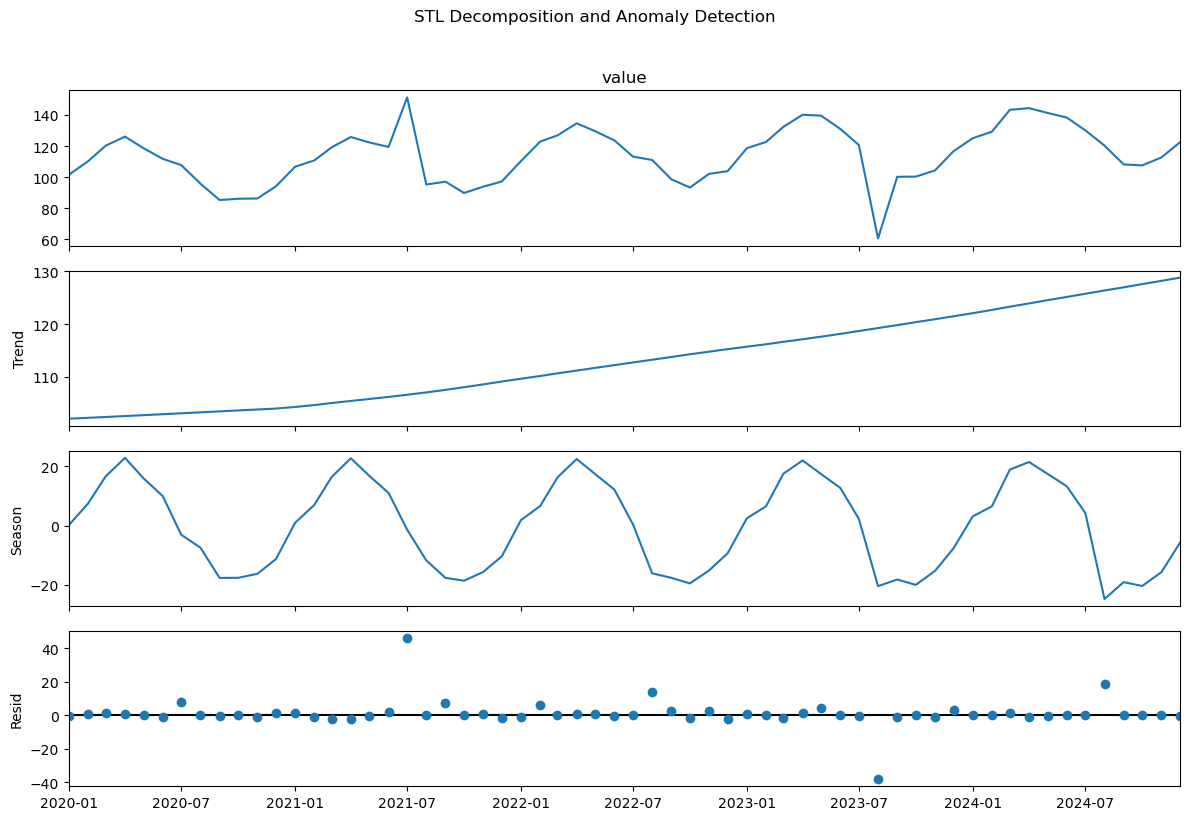

In [11]:
# STL 결과가 생성된 경우에만 시각화
if "stl_result" in globals():
    figure = stl_result.plot()

    figure.set_size_inches(
        12,
        8,
    )

    plt.suptitle(
        "STL Decomposition and Anomaly Detection",
        y=1.02,
    )

    plt.tight_layout()
    plt.show()

## 11. 최종 생성 파일 확인

최종적으로 다음 파일을 확인한다.

- `integrated_metadata.json`: 데이터셋과 STL·IQR 알고리즘 정보
- `stl_anomaly_result.csv`: STL 기반 이상 탐지 결과
- `iqr_anomaly_result.csv`: IQR 기반 이상 탐지 결과

In [12]:
# 최종 생성 파일 목록
output_files = [
    integrated_metadata_path,
] + result_files

# 파일 생성 여부 확인
for output_file in output_files:
    print(
        output_file.name,
        "->",
        output_file.exists(),
    )

integrated_metadata.json -> True
stl_anomaly_result.csv -> True
iqr_anomaly_result.csv -> True
